<ipython-input-3-591a106196ef>:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['Two_for_one'] = pd.to_numeric(df_filtered['Two_for_one'], errors='coerce')


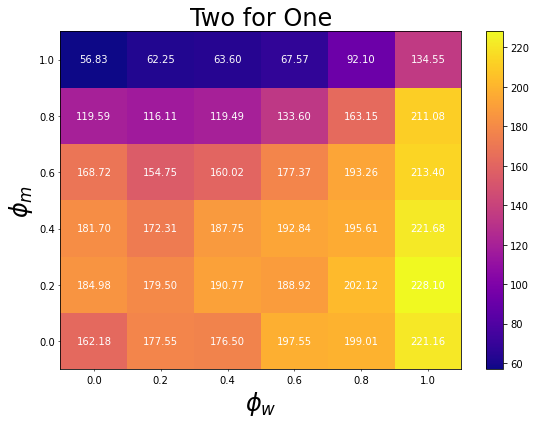

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("two_for_one_results_mallows.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['Phi1', 'Phi2', 'Two_for_one']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['Two_for_one'] = pd.to_numeric(df_filtered['Two_for_one'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['Two_for_one'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['Phi1'].unique())
phi2_vals = sorted(df_filtered['Phi2'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='Phi1', columns='Phi2', values='Two_for_one', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='plasma', norm=mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=np.nanmax(data_matrix)))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color='white')

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel(r'$\phi_w$', fontsize=24)
plt.ylabel(r'$\phi_m$', fontsize=24)
plt.title('Two for One', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("mallows_two_for_one.pdf", format='pdf')
plt.show()


<ipython-input-4-b9e12d9be049>:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['number_of_stable_matchings'] = pd.to_numeric(df_filtered['number_of_stable_matchings'], errors='coerce')


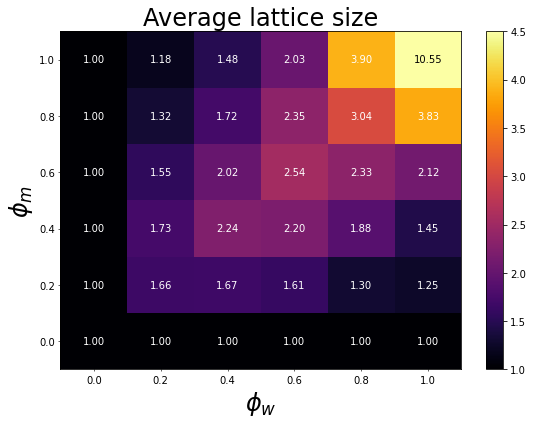

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("mallows_accomplice.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['phi_m', 'phi_w', 'number_of_stable_matchings']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['number_of_stable_matchings'] = pd.to_numeric(df_filtered['number_of_stable_matchings'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['number_of_stable_matchings'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['phi_m'].unique())
phi2_vals = sorted(df_filtered['phi_w'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='phi_m', columns='phi_w', values='number_of_stable_matchings', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='inferno', norm=mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=4.5))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell with different text color for last box
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            if i == data_matrix.shape[0] - 1 and j == data_matrix.shape[1] - 1:
                text_color = 'black'   # bottom-right cell text color
            else:
                text_color = 'white'   # other cells text color
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color=text_color)

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel(r'$\phi_w$', fontsize=24)
plt.ylabel(r'$\phi_m$', fontsize=24)
plt.title('Average lattice size', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("mallows_lattice.pdf", format='pdf')
plt.show()


<ipython-input-5-557c346ded61>:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['count_self_manipulating_women'] = pd.to_numeric(df_filtered['count_self_manipulating_women'], errors='coerce')


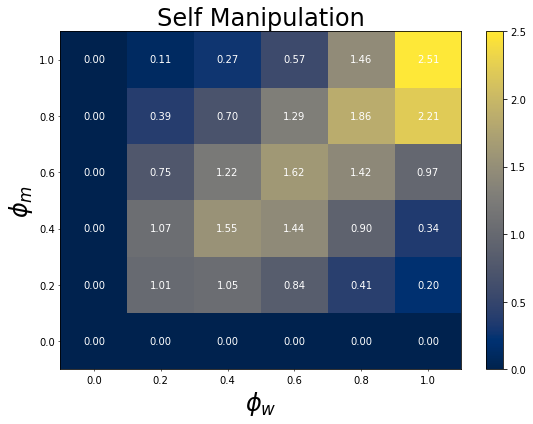

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("mallows_accomplice.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['phi_m', 'phi_w', 'count_self_manipulating_women']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['count_self_manipulating_women'] = pd.to_numeric(df_filtered['count_self_manipulating_women'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['count_self_manipulating_women'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['phi_m'].unique())
phi2_vals = sorted(df_filtered['phi_w'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='phi_m', columns='phi_w', values='count_self_manipulating_women', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='cividis', norm = mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=2.5))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color='white')

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel(r'$\phi_w$', fontsize=24)
plt.ylabel(r'$\phi_m$', fontsize=24)
plt.title('Self Manipulation', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("mallows_self.pdf", format='pdf')
plt.show()


<ipython-input-6-d2365f676360>:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['count_men'] = pd.to_numeric(df_filtered['count_men'], errors='coerce')


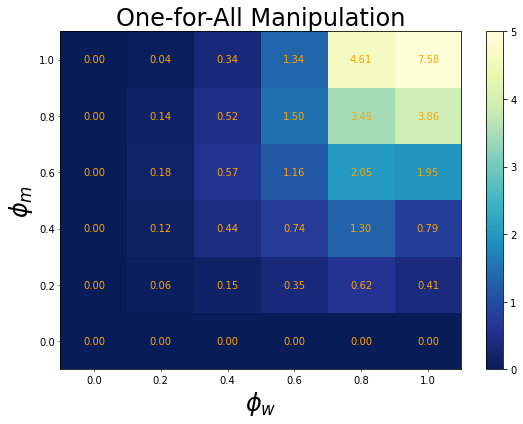

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("mallows_accomplice.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['phi_m', 'phi_w', 'count_men']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['count_men'] = pd.to_numeric(df_filtered['count_men'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['count_men'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['phi_m'].unique())
phi2_vals = sorted(df_filtered['phi_w'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='phi_m', columns='phi_w', values='count_men', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='YlGnBu_r', norm = mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=5))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color='orange')

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel(r'$\phi_w$', fontsize=24)
plt.ylabel(r'$\phi_m$', fontsize=24)
plt.title('One-for-All Manipulation', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("mallows_one_for_all.pdf", format='pdf')
plt.show()


<ipython-input-2-ec708977f5b8>:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['count_woman'] = pd.to_numeric(df_filtered['count_woman'], errors='coerce')


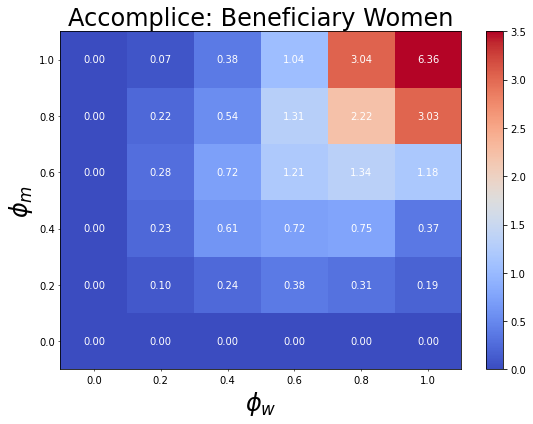

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("mallows_accomplice.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['phi_m', 'phi_w', 'count_woman']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['count_woman'] = pd.to_numeric(df_filtered['count_woman'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['count_woman'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['phi_m'].unique())
phi2_vals = sorted(df_filtered['phi_w'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='phi_m', columns='phi_w', values='count_woman', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='coolwarm', norm = mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=3.5))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color='white')

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel(r'$\phi_w$', fontsize=24)
plt.ylabel(r'$\phi_m$', fontsize=24)
plt.title('Accomplice: Beneficiary Women', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("mallows_acc_women.pdf", format='pdf')
plt.show()


<ipython-input-7-d8d8e2450545>:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['cnt_pairs'] = pd.to_numeric(df_filtered['cnt_pairs'], errors='coerce')


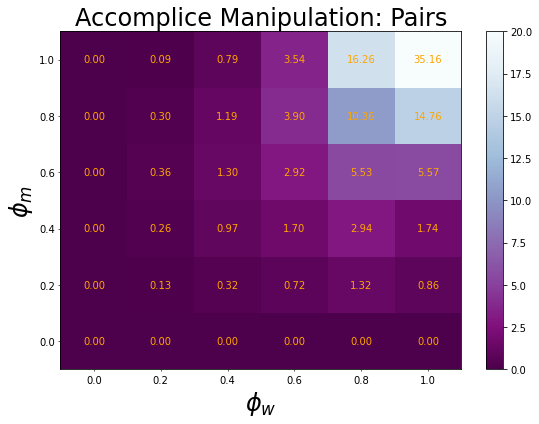

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("mallows_accomplice.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['phi_m', 'phi_w', 'cnt_pairs']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['cnt_pairs'] = pd.to_numeric(df_filtered['cnt_pairs'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['cnt_pairs'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['phi_m'].unique())
phi2_vals = sorted(df_filtered['phi_w'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='phi_m', columns='phi_w', values='cnt_pairs', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='BuPu_r', norm = mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=20))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color='orange')

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel(r'$\phi_w$', fontsize=24)
plt.ylabel(r'$\phi_m$', fontsize=24)
plt.title('Accomplice Manipulation: Pairs', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("mallows_acc_pairs.pdf", format='pdf')
plt.show()
